# Doubly Robust Evaluation

This native Julia companion preserves the public baskets, past-only context, 2018 standardization, action uniforms, fixed candidate policies, chronological folds and held-out split. Julia constructs all logged observations, fits reward models and computes every score. Zero/one action labels and zero-based policy numbers remain in the displayed results; native API calls use Julia indices. Figures use the requested dark theme and outputs are saved under `outputs/julia`.

## The Doubly Robust Score

Let $q(a,x)$ be a prediction of the reward under action $a$ at context $x$. The doubly robust estimate is

$$
\widehat V_{\mathrm{DR}}(\pi)
=\frac{1}{n}\sum_{i=1}^{n}
\left[
\sum_a\pi(a\mid X_i)\widehat q(a,X_i)
+\frac{\pi(A_i\mid X_i)}{\mu(A_i\mid X_i)}
\{Y_i-\widehat q(A_i,X_i)\}
\right].
$$

The first term averages predicted rewards under the target policy. The second term corrects the prediction using the logged reward. Under the usual one-step causal assumptions, the estimate remains valid when either the behavior probabilities or the reward prediction is correct, subject to regularity conditions.

Row,Case,IPW value,DR value,Known value,DR absolute error
,String,Float64,Float64,Float64,Float64
1,"Behavior correct, outcome wrong",4.4,4.4,4.4,8.88178e-16
2,"Behavior wrong, outcome correct",3.0,4.4,4.4,8.88178e-16
3,Both correct,4.4,4.4,4.4,8.88178e-16
4,Both wrong,3.0,3.0,4.4,1.4


Row,Case,Row,Action,Reward,Weight,IPW score,DR score
,String,Int64,Int64,Float64,Float64,Float64,Float64
1,"Behavior correct, outcome wrong",1,0,2.0,0.533333,1.06667,1.06667
2,"Behavior correct, outcome wrong",2,0,2.0,0.533333,1.06667,1.06667
3,"Behavior correct, outcome wrong",3,0,2.0,0.533333,1.06667,1.06667
4,"Behavior correct, outcome wrong",4,1,6.0,2.4,14.4,14.4
5,"Behavior wrong, outcome correct",1,0,2.0,0.8,1.6,4.4
6,"Behavior wrong, outcome correct",2,0,2.0,0.8,1.6,4.4
7,"Behavior wrong, outcome correct",3,0,2.0,0.8,1.6,4.4
8,"Behavior wrong, outcome correct",4,1,6.0,1.2,7.2,4.4
9,Both correct,1,0,2.0,0.533333,1.06667,4.4


Row,Fold,Training first date,Training last date,Prediction first date,Prediction last date,Training rows,Prediction rows,Training precedes prediction
,Int64,String,String,String,String,Int64,Int64,String
1,1,2019-01-02,2019-10-16,2019-10-17,2020-06-19,200,170,Pass
2,2,2019-01-02,2020-06-19,2020-06-22,2021-02-23,370,170,Pass
3,3,2019-01-02,2021-02-23,2021-02-24,2021-10-25,540,170,Pass
4,4,2019-01-02,2021-10-25,2021-10-26,2022-06-29,710,170,Pass
5,5,2019-01-02,2022-06-29,2022-06-30,2023-12-29,880,378,Pass


Row,Requirement,Status
,String,String
1,Every prediction fold follows its training dates,Pass
2,First policy-selection prediction starts after burn-in,Pass
3,Held-out predictions use only earlier dates,Pass
4,Prediction array matches rows and actions,Pass


Row,Action,Basket,Rows,Mean error,Mean absolute error,Root mean squared error,Correlation
,Int64,String,Int64,Float64,Float64,Float64,Float64
1,0,Defensive,1058,0.000305102,0.0080463,0.0125879,0.070791
2,1,Cyclical,1058,0.000481663,0.0150876,0.0220907,0.00326424


Row,Date,Observed action,Observed reward,Predicted defensive reward,Predicted cyclical reward
,String,Int64,Float64,Float64,Float64
1,2019-10-17,0,0.008325,-0.000839155,0.00400584
2,2020-03-09,1,-0.108625,0.00126467,0.0194605
3,2020-07-27,0,0.00555,0.00144872,-0.0018239
4,2020-12-11,0,-0.0034,0.00266441,0.001458
5,2021-05-04,0,-0.003525,-0.00169989,0.00114784
6,2021-09-21,0,-0.0011,-0.000620716,0.00198376
7,2022-02-08,1,0.023075,-0.00209268,-0.00142598
8,2022-06-29,0,-0.0021,0.00031553,-0.00368943


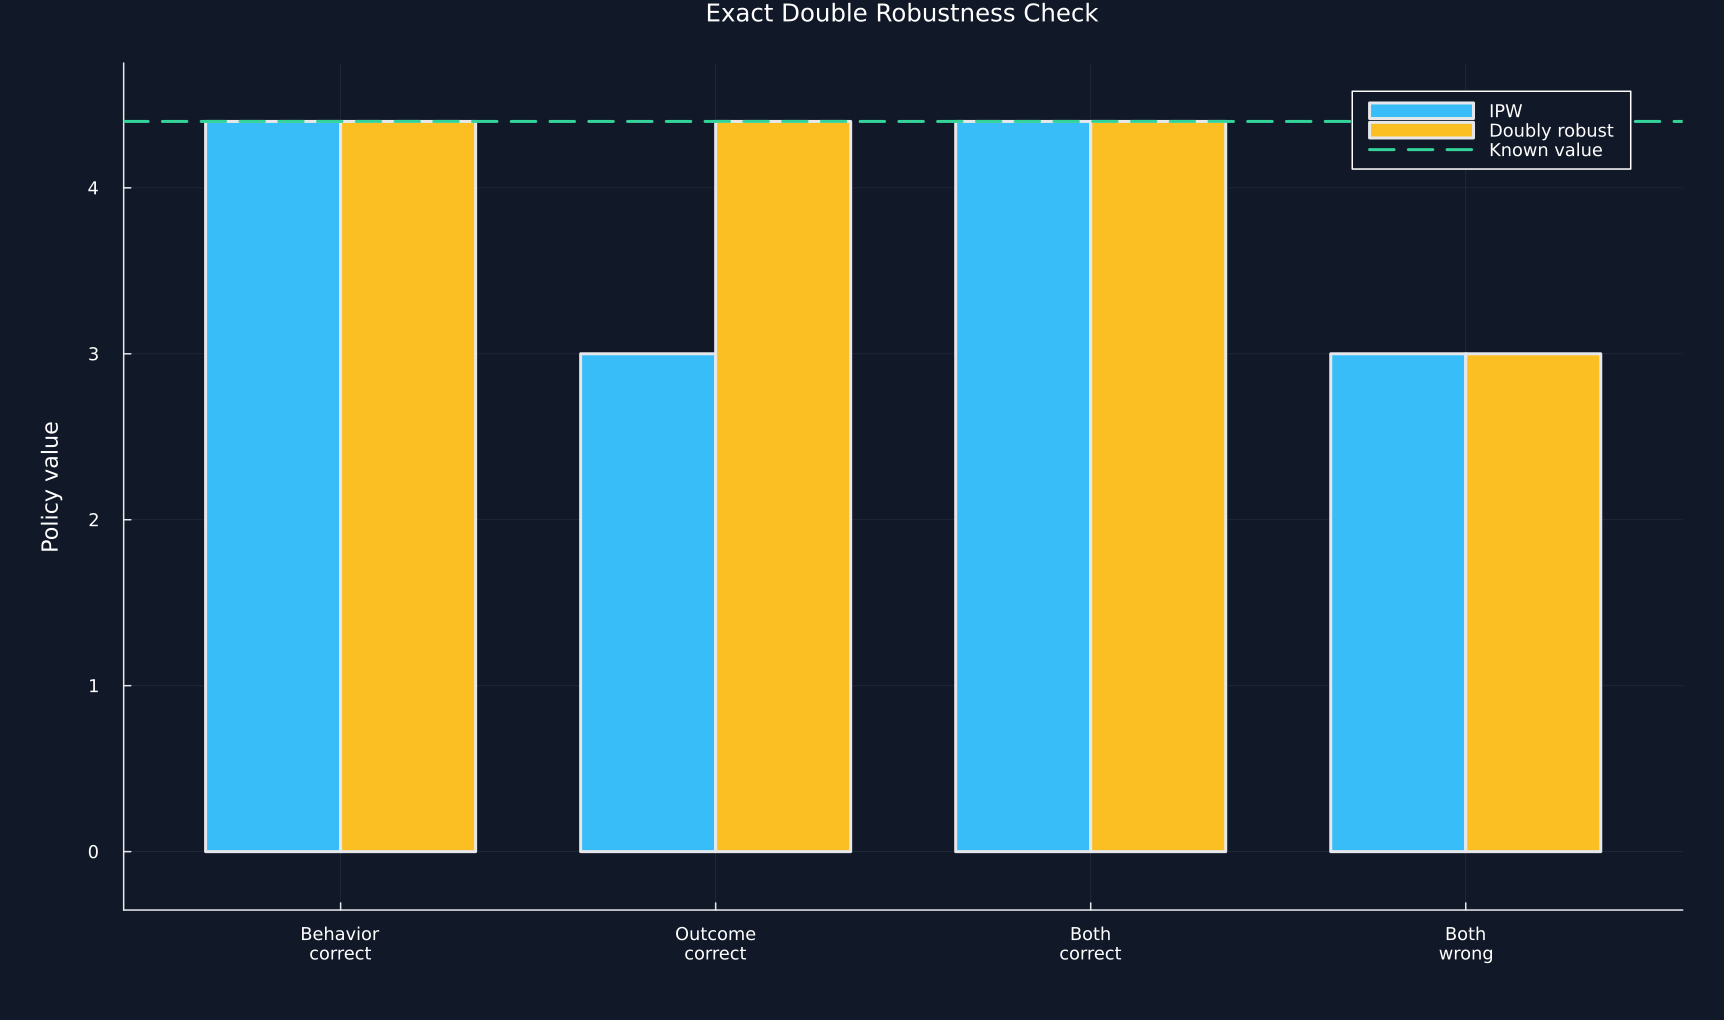

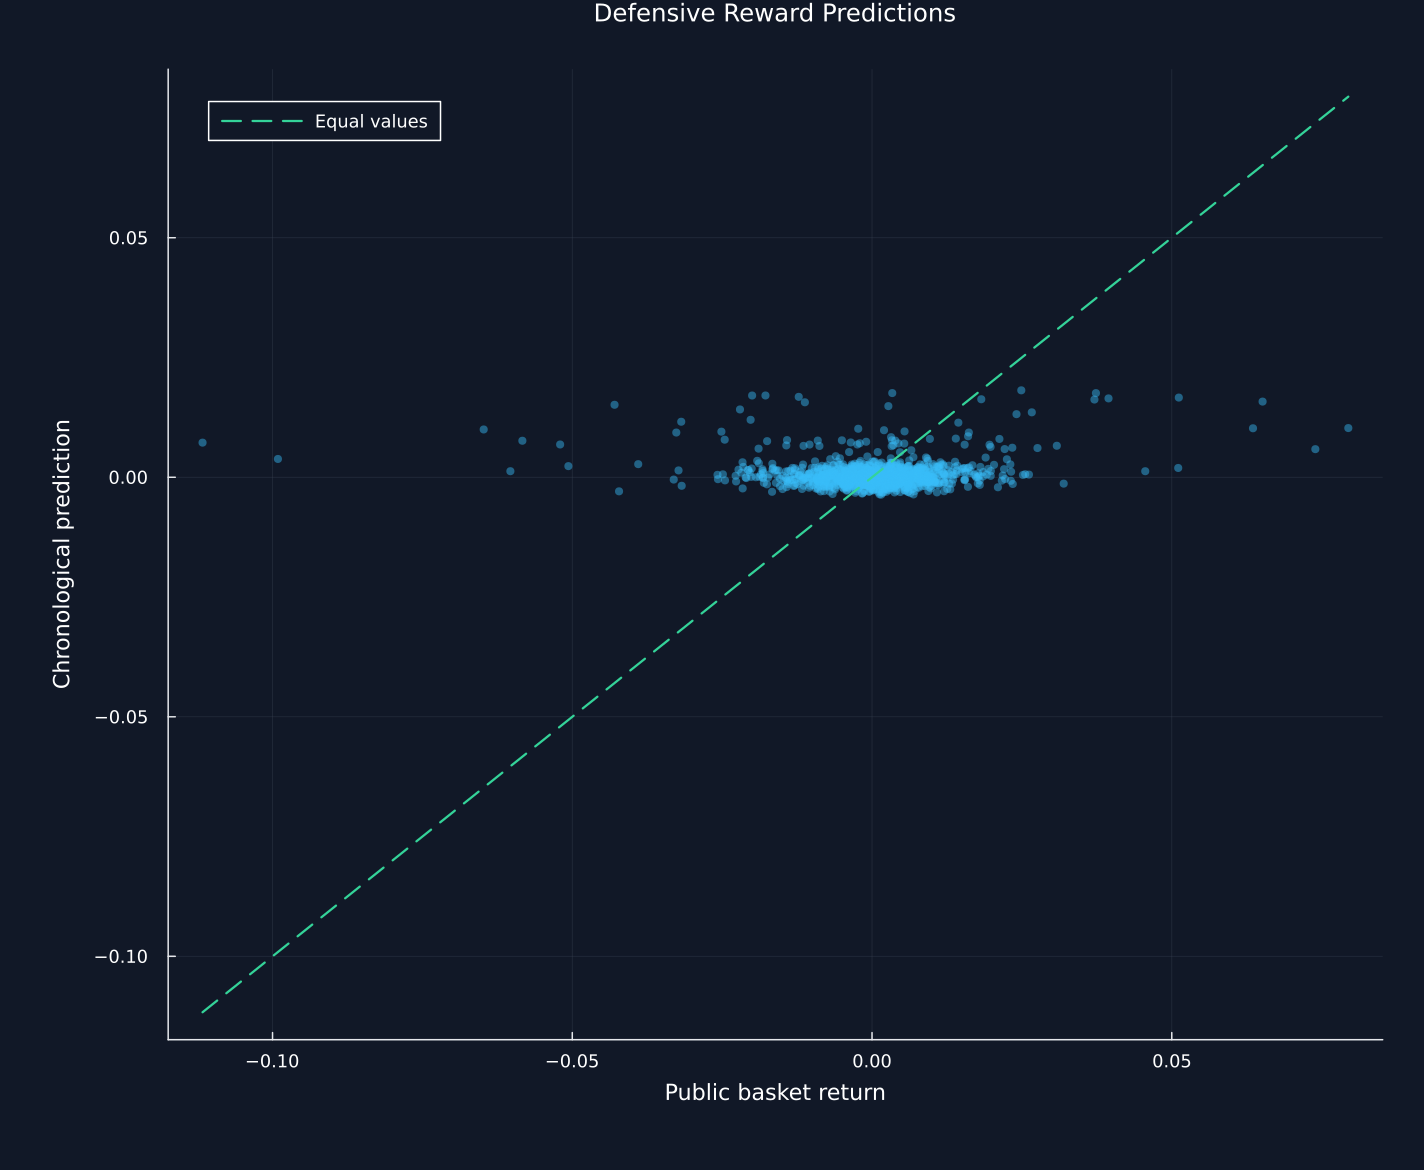

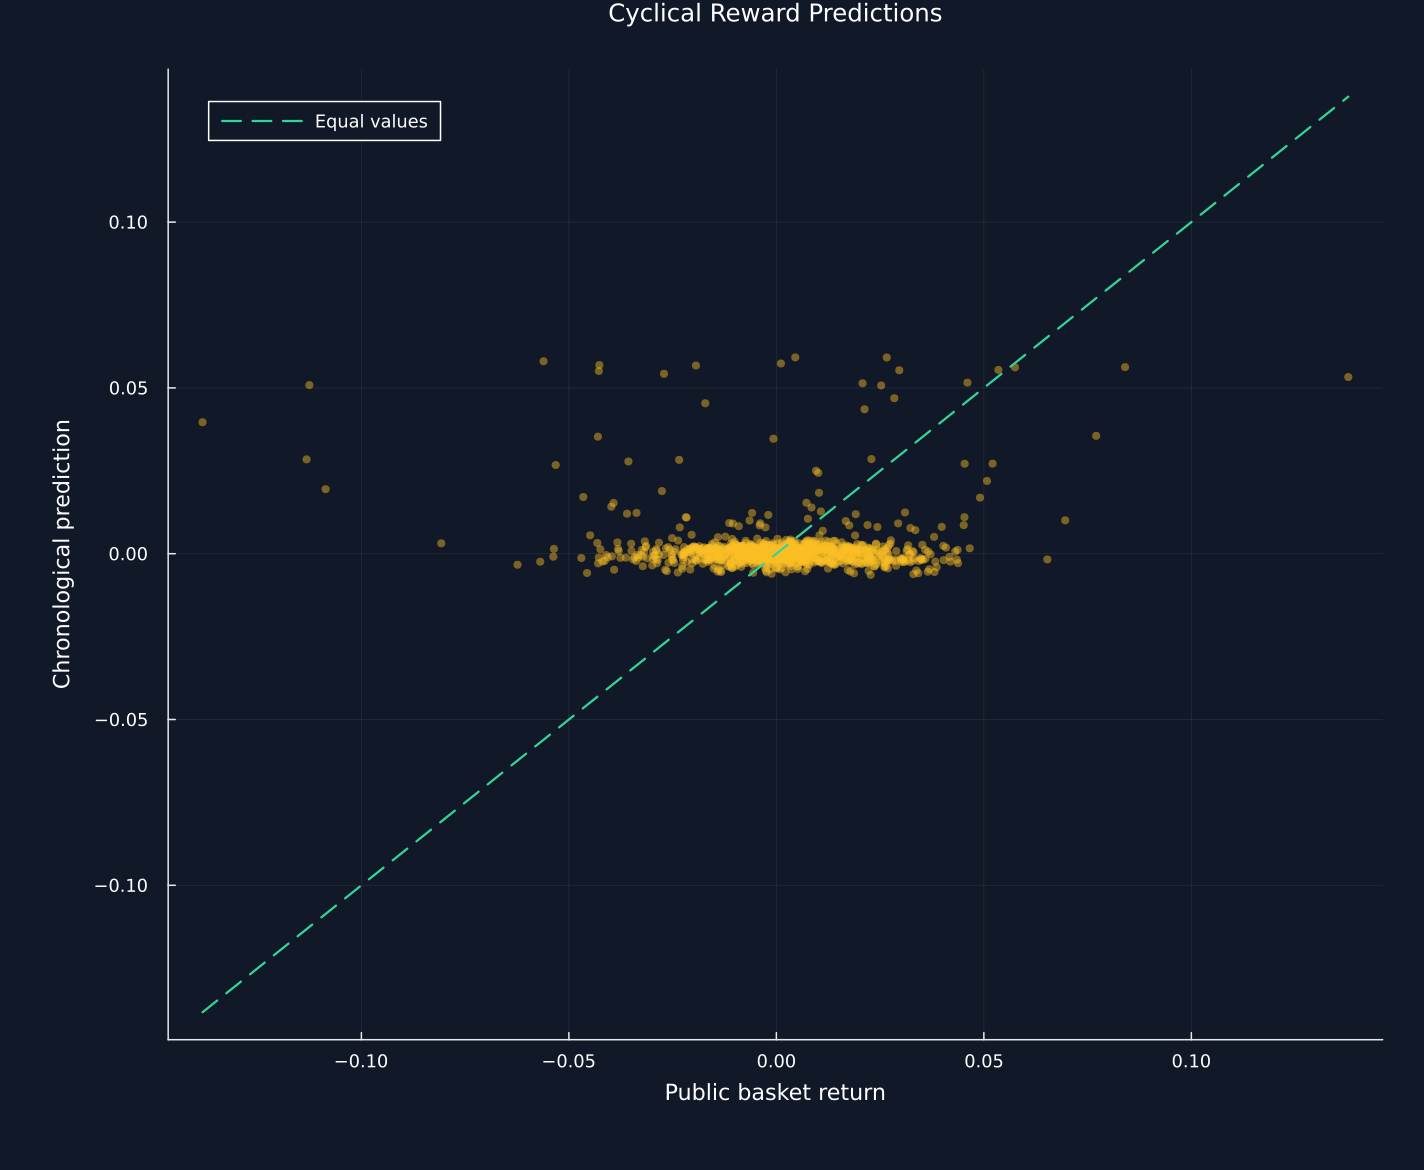

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("09_policy_evaluation");
using CSV,TOML,Printf
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy: PrimitiveStore,normal_block
include(joinpath("..","support","BookPolicyStudy.jl"))
using .BookPolicyStudy
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
store=PrimitiveStore(joinpath("..","data","chapter09_random_inputs"),"policy")
captions=Dict("ipw_data_provenance"=>"Provenance of the public returns used in the policy illustration.","ipw_basket_definitions"=>"Fixed public basket definitions.","ipw_sample_contract"=>"Data and decision contract for the illustration.","ipw_context_summary"=>"Summary of the past-only context variables.","ipw_behavior_summary"=>"Summary of the generated behavior policy and realized actions.","ipw_candidate_definitions"=>"Five fixed target policies.","ipw_policy_values"=>"Public full-information values and inverse probability estimates.","ipw_weight_summary"=>"Importance-weight diagnostics for the five target policies.","ipw_manual_score_rows"=>"First eight contributions for the smooth momentum policy.","ipw_support_checks"=>"Overlap and probability checks for the main target policy.","ipw_overlap_sensitivity"=>"Sensitivity of the smooth momentum estimate to the behavior probability floor.","ipw_invalid_support_checks"=>"Required rejections for invalid probability support.","ipw_section_summary"=>"Summary of the inverse probability illustration.","dr_exact_cases"=>"Exact four-row double robustness check.","dr_exact_scores"=>"Row contributions in the exact double robustness check.","dr_fold_plan"=>"Chronological reward-prediction folds.","dr_oof_checks"=>"Information-boundary checks for reward predictions.","dr_prediction_quality"=>"Quality of chronological reward predictions against both public basket returns.","dr_oof_sample_rows"=>"Selected chronological reward predictions from the policy-selection period.","dr_policy_comparison"=>"Held-out full-information, inverse probability, and doubly robust values.","dr_score_summary"=>"Held-out score distributions for the smooth momentum policy.","dr_nuisance_scenarios"=>"Algebraic nuisance-input diagnostics for the smooth momentum policy.","dr_invalid_input_checks"=>"Required rejections for incompatible policy-evaluation inputs.","dr_section_summary"=>"Summary of the doubly robust evaluation.","selection_split"=>"Chronological split used for policy selection and evaluation.","selection_training_values"=>"Earlier-period doubly robust values used for selection.","selection_heldout_values"=>"Held-out values shown after the earlier policy choice.","selection_result"=>"Result of chronological selection followed by held-out evaluation.","selection_policy_action_shares"=>"Average action-one probabilities of the fixed candidates.","selection_outcome_isolation"=>"Selection is unchanged when only held-out outcomes are replaced.","selection_tie_rule"=>"First-candidate rule for exactly equal training values.","selection_invalid_checks"=>"Required rejections for invalid chronological splits.","selection_final_diagnostics"=>"Diagnostics for the policy chosen on earlier dates.","selection_section_summary"=>"Summary of chronological policy selection.")
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption=captions[name],label="tab:cim9-"*replace(name,"_"=>"-"))
    return nothing
end
panel=build_policy_frame(store)
policy_names,candidates=candidate_policies(panel)
behavior=behavior_matrix(panel)
potential=potential_matrix(panel)
actions=panel.Action
rewards=panel[:,"Observed reward"]
predictions,fold_plan,fold_coefficients=chronological_predictions(panel)
exact_actions=[0,0,0,1]
exact_rewards=[2.,2.,2.,6.]
correct_behavior=repeat([.75 .25],4)
wrong_behavior=repeat([.5 .5],4)
target=repeat([.4 .6],4)
correct_outcome=repeat([2. 6.],4)
wrong_outcome=zeros(4,2)
exact_case_rows=[]
exact_score_rows=[]
for (name,supplied_behavior,supplied_outcome) in [("Behavior correct, outcome wrong",correct_behavior,wrong_outcome),("Behavior wrong, outcome correct",wrong_behavior,correct_outcome),("Both correct",correct_behavior,correct_outcome),("Both wrong",wrong_behavior,wrong_outcome)]
    result=policy_evaluation(exact_actions,exact_rewards,supplied_behavior,target,supplied_outcome)
    push!(exact_case_rows,(name,result.ipw_value,result.dr_value,4.4,abs(result.dr_value-4.4)))
    for index in 1:4
        push!(exact_score_rows,(name,index,exact_actions[index],exact_rewards[index],result.importance_weights[index],result.ipw_scores[index],result.dr_scores[index]))
    end
end
exact_cases=frame(["Case","IPW value","DR value","Known value","DR absolute error"],exact_case_rows)
exact_scores=frame(["Case","Row","Action","Reward","Weight","IPW score","DR score"],exact_score_rows)
table(exact_cases,"dr_exact_cases")
table(exact_scores,"dr_exact_scores")
insertcols!(fold_plan,1,"Fold"=>collect(1:nrow(fold_plan)))
table(fold_plan,"dr_fold_plan")
oof_checks=frame(["Requirement","Status"],[("Every prediction fold follows its training dates",all(fold_plan[:,"Training precedes prediction"])),("First policy-selection prediction starts after burn-in",fold_plan[1,"Training rows"]==200),("Held-out predictions use only earlier dates",fold_plan[end,"Training rows"]==880),("Prediction array matches rows and actions",size(predictions)==size(behavior))])
table(oof_checks,"dr_oof_checks")
prediction_rows=[]
evaluation_rows=collect(201:nrow(panel))
for (action,label) in [(0,"Defensive"),(1,"Cyclical")]
    actual=potential[evaluation_rows,action+1]
    predicted=predictions[evaluation_rows,action+1]
    push!(prediction_rows,(action,label,length(actual),mean(predicted-actual),mean(abs.(predicted-actual)),sqrt(mean((predicted-actual).^2)),cor(predicted,actual)))
end
prediction_quality=frame(["Action","Basket","Rows","Mean error","Mean absolute error","Root mean squared error","Correlation"],prediction_rows)
table(prediction_quality,"dr_prediction_quality")
sample_rows=floor.(Int,range(200,879;length=8)).+1
oof_sample=DataFrame("Date"=>string.(panel.Date[sample_rows]),"Observed action"=>actions[sample_rows],"Observed reward"=>rewards[sample_rows],"Predicted defensive reward"=>predictions[sample_rows,1],"Predicted cyclical reward"=>predictions[sample_rows,2])
table(oof_sample,"dr_oof_sample_rows")
save_data(exact_cases,paths,"dr_exact_cases")
positions=collect(1:4)
figure=bar(positions.-.18,exact_cases[:,2];bar_width=.36,color=palette.cyan,label="IPW",xticks=(positions,["Behavior\ncorrect","Outcome\ncorrect","Both\ncorrect","Both\nwrong"]),ylabel="Policy value",title="Exact Double Robustness Check",size=(1150,680))
bar!(figure,positions.+.18,exact_cases[:,3];bar_width=.36,color=palette.amber,label="Doubly robust")
hline!(figure,[4.4];color=palette.green,linewidth=2,linestyle=:dash,label="Known value")
bar_headroom!(figure,Matrix(exact_cases[:,2:3]))
save_figure(figure,paths,"dr_exact_cases")
for (action,stem,label,color) in [(1,"dr_oof_action0","Defensive",palette.cyan),(2,"dr_oof_action1","Cyclical",palette.amber)]
    plot_data=DataFrame("Actual reward"=>potential[evaluation_rows,action],"Predicted reward"=>predictions[evaluation_rows,action])
    save_data(plot_data,paths,stem)
    figure=scatter(plot_data[:,1],plot_data[:,2];color=color,markersize=3,alpha=.45,markerstrokewidth=0,label="",xlabel="Public basket return",ylabel="Chronological prediction",title=label*" Reward Predictions",size=(950,780))
    limits=[minimum(Matrix(plot_data)),maximum(Matrix(plot_data))]
    plot!(figure,limits,limits;color=palette.green,linewidth=1.5,linestyle=:dash,label="Equal values")
    save_figure(figure,paths,stem)
end


## Evaluating policy values from chronological predictions

The reward predictions used in the policy-selection period are formed in blocks. For each block, the model is fitted only on earlier logged rewards. The final period uses one model fitted on all earlier dates. This ordering prevents a date's outcome from helping predict itself or choose the final policy.

Because both basket returns are public, the full-information value can also be calculated as

$$
V_{\mathrm{full}}(\pi)
=\frac{1}{n}\sum_{i=1}^{n}\sum_{a\in\{0,1\}}
\pi(a\mid X_i)Y_i(a).
$$

Here, $Y_i(a)$ is the observed return of basket $a$ on date $i$. This benchmark checks the logged-data estimates in the illustration; it would normally be unavailable when only the chosen action's reward is observed.

Row,Policy,Full-information value,IPW value,DR value,IPW absolute error,DR absolute error,Effective sample size
,String,Float64,Float64,Float64,Float64,Float64,Float64
1,Always defensive,0.000134193,0.000425819,0.000336091,0.000291626,0.000201898,149.429
2,Always cyclical,0.00122956,0.00219942,0.00218732,0.000969856,0.000957753,167.881
3,Positive spread threshold,0.00095496,0.00115698,0.00118885,0.000202023,0.00023389,224.079
4,Smooth momentum,0.000966589,0.00127797,0.00127505,0.00031138,0.000308461,322.099
5,Volatility aware rule,0.000915362,0.00101196,0.00099393,9.65955e-5,7.85684e-5,345.419


Row,Score,Mean,Standard deviation,Minimum,Median,Maximum
,String,Float64,Float64,Float64,Float64,Float64
1,IPW,0.00127797,0.0161626,-0.0695805,0.000637788,0.0991738
2,Doubly robust,0.00127505,0.0162773,-0.0669345,0.00128817,0.103981


Row,Diagnostic case,IPW value,DR value,Full-information value,DR absolute error
,String,Float64,Float64,Float64,Float64
1,"Behavior correct, reward prediction zero",0.000470333,0.000470333,0.000913348,0.000443015
2,"Behavior set to one half, public rewards supplied",0.000882947,0.000913348,0.000913348,0.0
3,"Behavior correct, public rewards supplied",0.000470333,0.000913348,0.000913348,0.0
4,"Behavior set to one half, reward prediction zero",0.000882947,0.000882947,0.000913348,3.04007e-5


Row,Check,Rejected,Explanation
,String,String,String
1,Prediction matrix with one row missing,Pass,Stopped as required
2,Action outside the declared action set,Pass,Stopped as required
3,Target probability with incompatible shape,Pass,Stopped as required


Row,Result,Value
,String,String
1,Released exact check,Known value recovered when either nuisance input is correct
2,Reward predictions,Every evaluated date is predicted from earlier logged dates
3,Public benchmark,Both action rewards permit direct full-information comparison
4,Oracle diagnostic,Algebraic check only and not a deployable prediction method
5,Final-period role,Evaluation only after policy selection


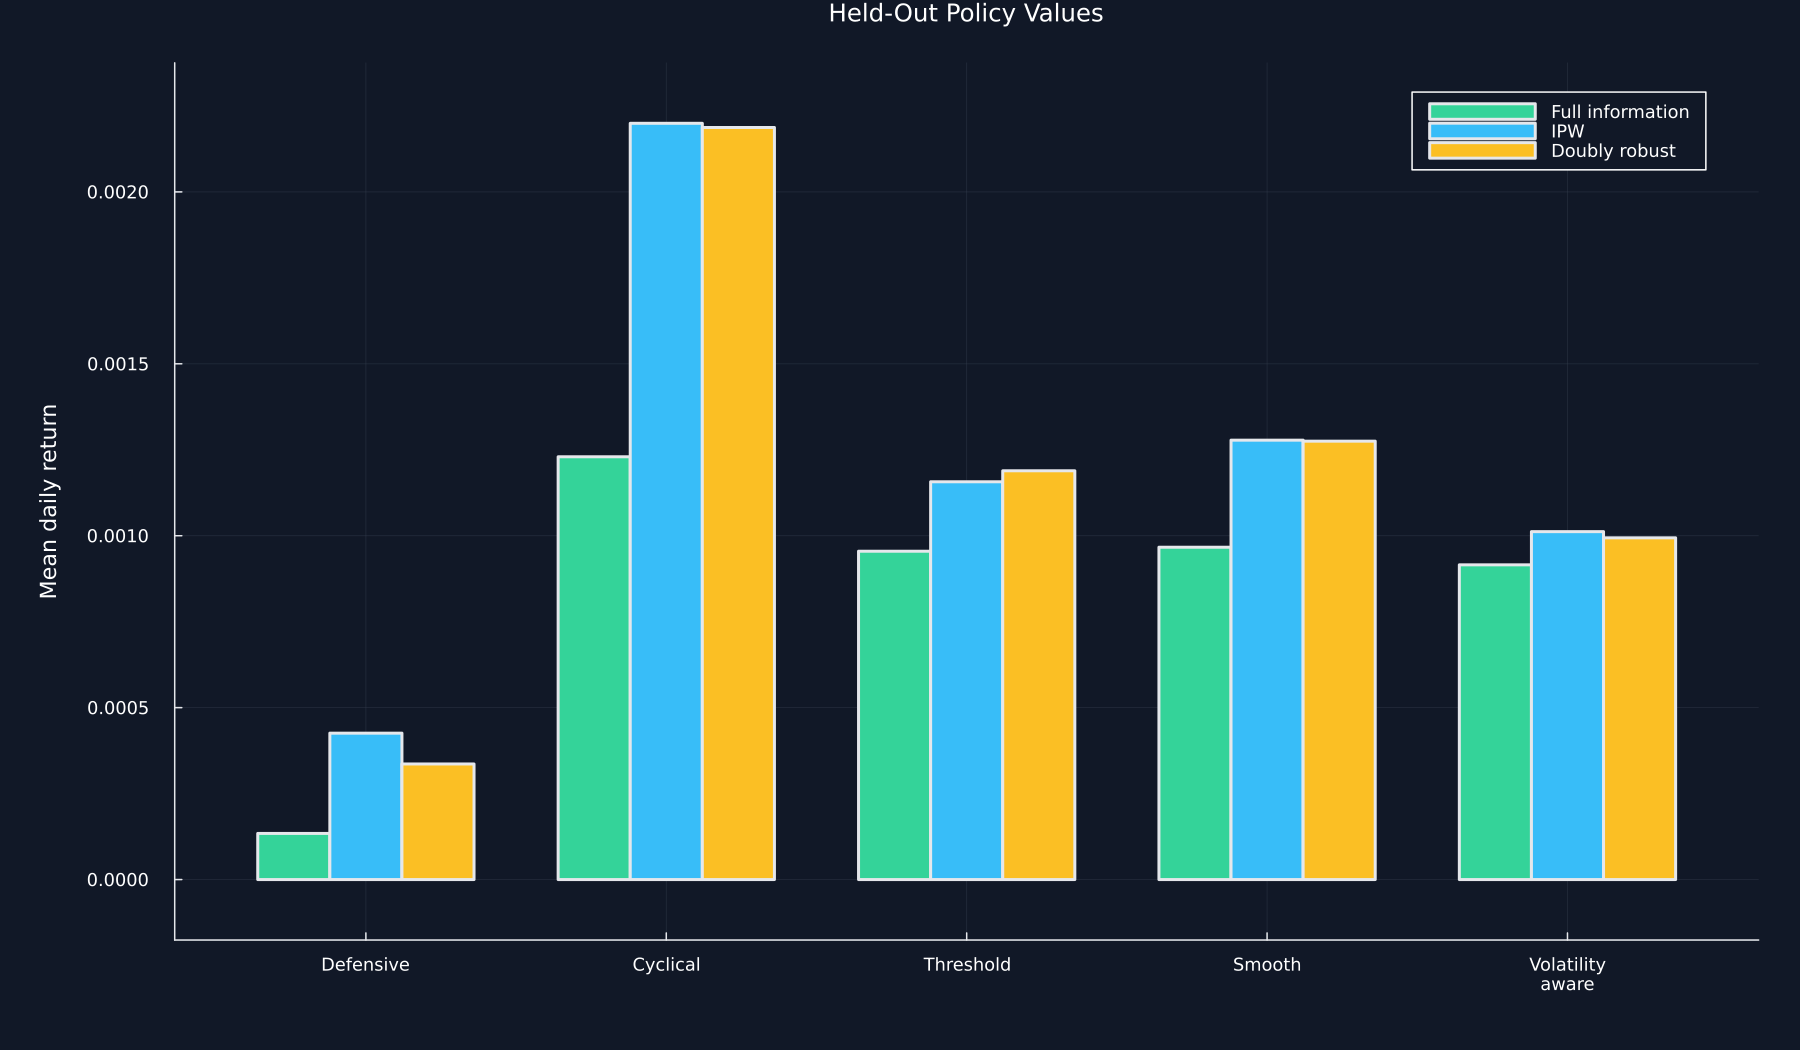

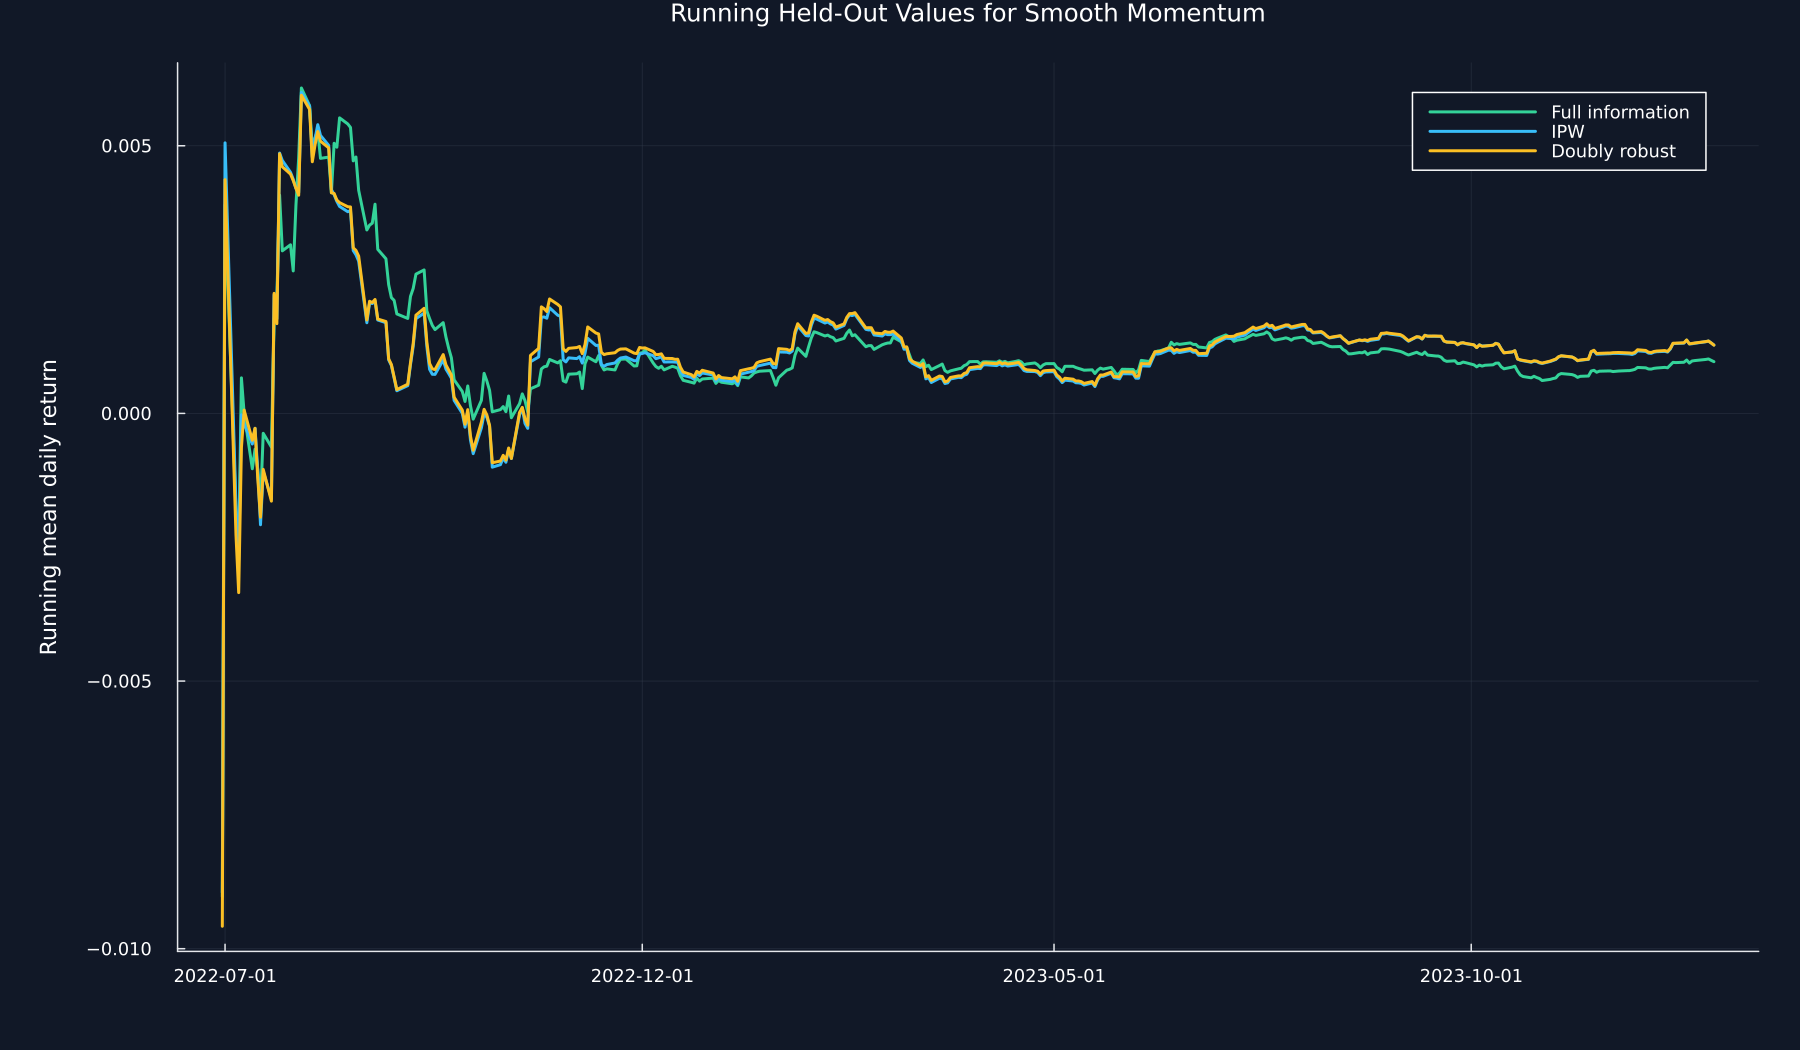

In [2]:
heldout=collect(881:nrow(panel))
comparison_rows=[]
heldout_score_rows=[]
for (index,name) in enumerate(policy_names)
    policy=candidates[index,:,:]
    result=policy_evaluation(actions[heldout],rewards[heldout],behavior[heldout,:],policy[heldout,:],predictions[heldout,:])
    truth=full_information_value(panel,policy,heldout)
    push!(comparison_rows,(name,truth,result.ipw_value,result.dr_value,abs(result.ipw_value-truth),abs(result.dr_value-truth),result.effective_sample_size))
    for (position,row) in enumerate(heldout)
        push!(heldout_score_rows,(index-1,panel.Date[row],result.importance_weights[position],result.ipw_scores[position],result.dr_scores[position]))
    end
end
comparison=frame(["Policy","Full-information value","IPW value","DR value","IPW absolute error","DR absolute error","Effective sample size"],comparison_rows)
table(comparison,"dr_policy_comparison")
save_data(frame(["Policy number","Date","Importance weight","IPW score","DR score"],heldout_score_rows),paths,"policy_all_heldout_scores")
smooth=candidates[4,:,:]
smooth_result=policy_evaluation(actions[heldout],rewards[heldout],behavior[heldout,:],smooth[heldout,:],predictions[heldout,:])
score_summary=frame(["Score","Mean","Standard deviation","Minimum","Median","Maximum"],[(name,mean(scores),std(scores;corrected=true),minimum(scores),median(scores),maximum(scores)) for (name,scores) in [("IPW",smooth_result.ipw_scores),("Doubly robust",smooth_result.dr_scores)]])
table(score_summary,"dr_score_summary")
oracle=copy(potential)
wrong_probability=fill(.5,size(behavior))
zero_prediction=zeros(size(predictions))
diagnostic_rows=collect(201:nrow(panel))
nuisance_rows=[]
for (name,supplied_behavior,supplied_predictions) in [("Behavior correct, reward prediction zero",behavior,zero_prediction),("Behavior set to one half, public rewards supplied",wrong_probability,oracle),("Behavior correct, public rewards supplied",behavior,oracle),("Behavior set to one half, reward prediction zero",wrong_probability,zero_prediction)]
    result=policy_evaluation(actions[diagnostic_rows],rewards[diagnostic_rows],supplied_behavior[diagnostic_rows,:],smooth[diagnostic_rows,:],supplied_predictions[diagnostic_rows,:])
    truth=full_information_value(panel,smooth,diagnostic_rows)
    push!(nuisance_rows,(name,result.ipw_value,result.dr_value,truth,abs(result.dr_value-truth)))
end
nuisance_scenarios=frame(["Diagnostic case","IPW value","DR value","Full-information value","DR absolute error"],nuisance_rows)
table(nuisance_scenarios,"dr_nuisance_scenarios")
invalid_checks=frame(["Check","Rejected","Explanation"],[capture_failure("Prediction matrix with one row missing",()->policy_evaluation(actions,rewards,behavior,candidates[1,:,:],predictions[1:end-1,:])),capture_failure("Action outside the declared action set",()->policy_evaluation(vcat(2,actions[2:end]),rewards,behavior,candidates[1,:,:],predictions)),capture_failure("Target probability with incompatible shape",()->policy_evaluation(actions,rewards,behavior,candidates[1,:,1:1],predictions))])
table(invalid_checks,"dr_invalid_input_checks")
section_summary = frame(["Result","Value"],[["Released exact check","Known value recovered when either nuisance input is correct"],["Reward predictions","Every evaluated date is predicted from earlier logged dates"],["Public benchmark","Both action rewards permit direct full-information comparison"],["Oracle diagnostic","Algebraic check only and not a deployable prediction method"],["Final-period role","Evaluation only after policy selection"]])
table(section_summary,"dr_section_summary")
save_data(comparison,paths,"dr_policy_values")
positions=collect(1:5)
figure=bar(positions.-.24,comparison[:,2];bar_width=.24,color=palette.green,label="Full information",xticks=(positions,["Defensive","Cyclical","Threshold","Smooth","Volatility\naware"]),ylabel="Mean daily return",title="Held-Out Policy Values",size=(1200,700))
bar!(figure,positions,comparison[:,3];bar_width=.24,color=palette.cyan,label="IPW")
bar!(figure,positions.+.24,comparison[:,4];bar_width=.24,color=palette.amber,label="Doubly robust")
bar_headroom!(figure,Matrix(comparison[:,2:4]))
save_figure(figure,paths,"dr_policy_values")
full_scores=vec(sum(smooth[heldout,:].*potential[heldout,:];dims=2))
denominator=collect(1:length(heldout))
running=DataFrame("Date"=>panel.Date[heldout],"Full information"=>cumsum(full_scores)./denominator,"IPW"=>cumsum(smooth_result.ipw_scores)./denominator,"Doubly robust"=>cumsum(smooth_result.dr_scores)./denominator)
save_data(running,paths,"dr_running_values")
figure=plot(running.Date,Matrix(running[:,2:4]);color=[palette.green palette.cyan palette.amber],label=["Full information" "IPW" "Doubly robust"],ylabel="Running mean daily return",title="Running Held-Out Values for Smooth Momentum",size=(1200,700))
save_figure(figure,paths,"dr_running_values")
